In [8]:
import os

print("Attached files:\n")

for dirname, _, filenames in os.walk("/kaggle/input"):
    if filenames:
        print(dirname, "->", len(filenames), "files")

Attached files:

/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Late_blight -> 792 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Tomato_Yellow_Leaf_Curl_Virus -> 498 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Septoria_leaf_spot -> 746 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Early_blight -> 643 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Spider_mites Two-spotted_spider_mite -> 435 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/powdery_mildew -> 252 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/healthy -> 806 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Bacterial_spot -> 732 files
/kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/Target_Spot -> 457 files
/kaggle/input/datasets/cookiefinder/tom

KeyboardInterrupt: 

In [ ]:
import os
from pathlib import Path

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{Path(root).name}/")

        for d in dirs[:20]:
            print(f"{indent}    {d}/")

In [ ]:
import os
from pathlib import Path

print("Kaggle input structure:\n")

for root, dirs, files in os.walk("/kaggle/input"):
    level = root.replace("/kaggle/input", "").count(os.sep)

    if level <= 4:
        indent = "    " * level
        print(f"{indent}{Path(root).name}/")

        for d in dirs[:30]:
            print(f"{indent}    {d}/")

In [ ]:
import os
from collections import defaultdict

image_exts = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

class_counts = defaultdict(int)

for root, _, files in os.walk("/kaggle/input"):
    valid_images = [
        f for f in files
        if f.lower().endswith(image_exts)
    ]

    if valid_images:
        class_name = os.path.basename(root)
        class_counts[class_name] += len(valid_images)

print("IMAGE COUNTS BY FOLDER:\n")

for cls, count in sorted(
    class_counts.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{cls:45s} {count}")

print("\nTotal images:", sum(class_counts.values()))

In [ ]:
from pathlib import Path
import os
import pandas as pd

DATA_ROOT = Path(
    "/kaggle/input/datasets/cookiefinder/"
    "tomato-disease-multiple-sources"
)

TRAIN_DIR = DATA_ROOT / "train"
VALID_DIR = DATA_ROOT / "valid"

print("Train exists:", TRAIN_DIR.exists())
print("Valid exists:", VALID_DIR.exists())

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_split(split_dir):
    rows = []

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.rglob("*")
                if p.suffix.lower() in image_exts
            )

            rows.append({
                "class": class_dir.name,
                "images": count
            })

    return pd.DataFrame(rows)

train_counts = count_split(TRAIN_DIR)
valid_counts = count_split(VALID_DIR)

comparison = train_counts.merge(
    valid_counts,
    on="class",
    how="outer",
    suffixes=("_train", "_valid")
).fillna(0)

comparison["total"] = (
    comparison["images_train"] +
    comparison["images_valid"]
)

display(comparison)

print("Training images  :", int(comparison["images_train"].sum()))
print("Validation images:", int(comparison["images_valid"].sum()))
print("Total            :", int(comparison["total"].sum()))

print("\nTrain classes:", len(train_counts))
print("Valid classes:", len(valid_counts))

In [ ]:
from PIL import Image
from pathlib import Path

corrupt_files = []

all_image_files = []

for split_dir in [TRAIN_DIR, VALID_DIR]:
    for path in split_dir.rglob("*"):
        if path.suffix.lower() in image_exts:
            all_image_files.append(path)

print("Checking", len(all_image_files), "images...")

for i, path in enumerate(all_image_files, start=1):
    try:
        with Image.open(path) as img:
            img.verify()

    except Exception as e:
        corrupt_files.append({
            "file": str(path),
            "error": str(e)
        })

    if i % 5000 == 0:
        print(f"Checked {i}/{len(all_image_files)}")

print("\nCorrupt images:", len(corrupt_files))

if corrupt_files:
    display(pd.DataFrame(corrupt_files).head(50))
else:
    print("✅ All images passed integrity check.")

In [9]:
# ============================================================
# NAMMA KRUSHI - FINAL DISEASE DATASET SPLIT
# ============================================================

from pathlib import Path
import pandas as pd
import json
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

DATA_ROOT = Path(
    "/kaggle/input/datasets/cookiefinder/"
    "tomato-disease-multiple-sources"
)

TRAIN_DIR = DATA_ROOT / "train"
OFFICIAL_VALID_DIR = DATA_ROOT / "valid"

OUTPUT_DIR = Path(
    "/kaggle/working/namma_krushi_disease"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

image_exts = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# ------------------------------------------------------------
# 2. CORRUPT FILES FOUND IN PREVIOUS CHECK
# ------------------------------------------------------------

corrupt_set = {
    str(Path(item["file"]))
    for item in corrupt_files
}

print("Corrupt files to exclude:", len(corrupt_set))

for p in corrupt_set:
    print(" -", p)


# ------------------------------------------------------------
# 3. BUILD IMAGE MANIFEST
# ------------------------------------------------------------

def build_manifest(root_dir):

    records = []

    for class_dir in sorted(root_dir.iterdir()):

        if not class_dir.is_dir():
            continue

        class_name = class_dir.name

        for path in class_dir.rglob("*"):

            if path.suffix.lower() not in image_exts:
                continue

            if str(path) in corrupt_set:
                continue

            records.append({
                "filepath": str(path),
                "class_name": class_name
            })

    return pd.DataFrame(records)


original_train_df = build_manifest(
    TRAIN_DIR
)

official_test_df = build_manifest(
    OFFICIAL_VALID_DIR
)

print("\nOriginal training images:",
      len(original_train_df))

print("Official test images:",
      len(official_test_df))


# ------------------------------------------------------------
# 4. FINAL CLASS ORDER
# ------------------------------------------------------------

CLASS_NAMES = sorted(
    original_train_df["class_name"].unique()
)

CLASS_TO_INDEX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

INDEX_TO_CLASS = {
    idx: name
    for name, idx in CLASS_TO_INDEX.items()
}

print("\n" + "=" * 80)
print("FINAL CLASS MAPPING")
print("=" * 80)

for idx, name in enumerate(CLASS_NAMES):
    print(f"{idx:2d} -> {name}")


# ------------------------------------------------------------
# 5. ADD NUMERIC LABELS
# ------------------------------------------------------------

original_train_df["label"] = (
    original_train_df["class_name"]
    .map(CLASS_TO_INDEX)
)

official_test_df["label"] = (
    official_test_df["class_name"]
    .map(CLASS_TO_INDEX)
)


# ------------------------------------------------------------
# 6. SPLIT ORIGINAL TRAIN INTO TRAIN + VALIDATION
# ------------------------------------------------------------

train_df, val_df = train_test_split(
    original_train_df,
    test_size=0.10,
    random_state=42,
    stratify=original_train_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = official_test_df.reset_index(drop=True)


# ------------------------------------------------------------
# 7. VALIDATE ALL CLASSES EXIST IN ALL SPLITS
# ------------------------------------------------------------

assert train_df["class_name"].nunique() == 11
assert val_df["class_name"].nunique() == 11
assert test_df["class_name"].nunique() == 11

assert set(train_df["class_name"]) == set(CLASS_NAMES)
assert set(val_df["class_name"]) == set(CLASS_NAMES)
assert set(test_df["class_name"]) == set(CLASS_NAMES)


# ------------------------------------------------------------
# 8. SPLIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL DATASET SPLIT")
print("=" * 80)

print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Final Test :", len(test_df))

print(
    "\nTotal valid images:",
    len(train_df) + len(val_df) + len(test_df)
)


# ------------------------------------------------------------
# 9. CLASS DISTRIBUTION
# ------------------------------------------------------------

split_counts = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "validation": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts()
}).fillna(0).astype(int)

split_counts["total"] = (
    split_counts["train"]
    + split_counts["validation"]
    + split_counts["test"]
)

split_counts = split_counts.loc[
    CLASS_NAMES
]

display(split_counts)


# ------------------------------------------------------------
# 10. SAVE MANIFESTS
# ------------------------------------------------------------

train_df.to_csv(
    OUTPUT_DIR / "train_manifest.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation_manifest.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / "test_manifest.csv",
    index=False
)


# ------------------------------------------------------------
# 11. SAVE CLASS CONFIGURATION
# ------------------------------------------------------------

with open(
    OUTPUT_DIR / "class_names.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        CLASS_NAMES,
        f,
        indent=2
    )


with open(
    OUTPUT_DIR / "class_mapping.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        CLASS_TO_INDEX,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 12. SAVE DATASET INFO
# ------------------------------------------------------------

dataset_info = {

    "total_original_images": 32535,

    "corrupt_images_excluded":
        len(corrupt_set),

    "valid_images":
        int(
            len(train_df)
            + len(val_df)
            + len(test_df)
        ),

    "training_images":
        int(len(train_df)),

    "validation_images":
        int(len(val_df)),

    "test_images":
        int(len(test_df)),

    "number_of_classes":
        len(CLASS_NAMES),

    "split_strategy":
        (
            "90/10 stratified split of original train folder; "
            "original valid folder reserved as untouched final test set"
        )
}

with open(
    OUTPUT_DIR / "dataset_info.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_info,
        f,
        indent=2
    )


print("\nSaved:")

for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Corrupt files to exclude: 1
 - /kaggle/input/datasets/cookiefinder/tomato-disease-multiple-sources/valid/healthy/HL_(336).png

Original training images: 25851
Official test images: 6683

FINAL CLASS MAPPING
 0 -> Bacterial_spot
 1 -> Early_blight
 2 -> Late_blight
 3 -> Leaf_Mold
 4 -> Septoria_leaf_spot
 5 -> Spider_mites Two-spotted_spider_mite
 6 -> Target_Spot
 7 -> Tomato_Yellow_Leaf_Curl_Virus
 8 -> Tomato_mosaic_virus
 9 -> healthy
10 -> powdery_mildew

FINAL DATASET SPLIT
Training   : 23265
Validation : 2586
Final Test : 6683

Total valid images: 32534


,train,validation,test,total
class_name,,,,
Bacterial_spot,2543,283,732,3558
Early_blight,2209,246,643,3098
Late_blight,2802,311,792,3905
Leaf_Mold,2478,276,739,3493
Septoria_leaf_spot,2594,288,746,3628
Spider_mites Two-spotted_spider_mite,1572,175,435,2182
Target_Spot,1644,183,457,2284
Tomato_Yellow_Leaf_Curl_Virus,1835,204,498,2537
Tomato_mosaic_virus,1938,215,584,2737



Saved:
 - class_mapping.json
 - class_names.json
 - dataset_info.json
 - test_manifest.csv
 - train_manifest.csv
 - validation_manifest.csv


In [ ]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))

In [10]:
# ============================================================
# RECREATE DISEASE MANIFESTS AFTER KAGGLE SESSION RESTART
# ============================================================

from pathlib import Path
import pandas as pd
import json
from sklearn.model_selection import train_test_split

DATA_ROOT = Path(
    "/kaggle/input/datasets/cookiefinder/"
    "tomato-disease-multiple-sources"
)

TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "valid"

OUTPUT_DIR = Path(
    "/kaggle/working/namma_krushi_disease"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

# Known corrupt image found previously
CORRUPT_FILE = str(
    TEST_DIR / "healthy" / "HL_(336).png"
)

def build_manifest(root_dir):
    rows = []

    for class_dir in sorted(root_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.suffix.lower() not in IMAGE_EXTS:
                continue

            if str(path) == CORRUPT_FILE:
                continue

            rows.append({
                "filepath": str(path),
                "class_name": class_dir.name
            })

    return pd.DataFrame(rows)


# Load original folders
original_train_df = build_manifest(TRAIN_DIR)
test_df = build_manifest(TEST_DIR)

# Stable class order
CLASS_NAMES = sorted(
    original_train_df["class_name"].unique()
)

CLASS_TO_INDEX = {
    name: idx
    for idx, name in enumerate(CLASS_NAMES)
}

original_train_df["label"] = (
    original_train_df["class_name"]
    .map(CLASS_TO_INDEX)
)

test_df["label"] = (
    test_df["class_name"]
    .map(CLASS_TO_INDEX)
)

# Same 90/10 stratified split as before
train_df, val_df = train_test_split(
    original_train_df,
    test_size=0.10,
    random_state=42,
    stratify=original_train_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Save manifests
train_df.to_csv(
    OUTPUT_DIR / "train_manifest.csv",
    index=False
)

val_df.to_csv(
    OUTPUT_DIR / "validation_manifest.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_DIR / "test_manifest.csv",
    index=False
)

with open(
    OUTPUT_DIR / "class_names.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(CLASS_NAMES, f, indent=2)

with open(
    OUTPUT_DIR / "class_mapping.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(CLASS_TO_INDEX, f, indent=2)

print("Training   :", len(train_df))
print("Validation :", len(val_df))
print("Final Test :", len(test_df))

print("\nFiles recreated:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Training   : 23265
Validation : 2586
Final Test : 6683

Files recreated:
 - class_mapping.json
 - class_names.json
 - dataset_info.json
 - test_manifest.csv
 - train_manifest.csv
 - validation_manifest.csv


In [11]:
import tensorflow as tf
import pandas as pd
import numpy as np
import json
from pathlib import Path

BASE_DIR = Path("/kaggle/working/namma_krushi_disease")

train_df = pd.read_csv(BASE_DIR / "train_manifest.csv")
val_df = pd.read_csv(BASE_DIR / "validation_manifest.csv")
test_df = pd.read_csv(BASE_DIR / "test_manifest.csv")

with open(
    BASE_DIR / "class_names.json",
    "r",
    encoding="utf-8"
) as f:
    CLASS_NAMES = json.load(f)

NUM_CLASSES = len(CLASS_NAMES)

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32)

    return image, label


def make_dataset(dataframe, training=False):

    paths = dataframe["filepath"].astype(str).values
    labels = dataframe["label"].astype(np.int32).values

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            10000,
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(AUTOTUNE)

    return ds


train_ds = make_dataset(
    train_df,
    training=True
)

val_ds = make_dataset(
    val_df,
    training=False
)

test_ds = make_dataset(
    test_df,
    training=False
)

images, labels = next(iter(train_ds))

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Classes:", NUM_CLASSES)

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print(
    "Pixel range:",
    float(tf.reduce_min(images)),
    "to",
    float(tf.reduce_max(images))
)

print("Example labels:", labels[:10].numpy())

print("\n✅ CNN data pipeline ready")

I0000 00:00:1788525658.281771      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Train: 23265
Validation: 2586
Test: 6683
Classes: 11

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 255.0
Example labels: [ 9  3  8  1  1  2 10  1  8  1]

✅ CNN data pipeline ready


In [12]:
# ============================================================
# NAMMA KRUSHI - BUILD EFFICIENTNETB0 TOMATO DISEASE MODEL
# ============================================================

import tensorflow as tf
import numpy as np

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 1. CLASS WEIGHTS
# ============================================================

classes = np.unique(train_df["label"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"]
)

CLASS_WEIGHTS = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

for idx, weight in CLASS_WEIGHTS.items():
    print(
        f"{idx:2d} "
        f"{CLASS_NAMES[idx]:45s} "
        f"{weight:.3f}"
    )


# ============================================================
# 2. DATA AUGMENTATION
# ============================================================

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)


# ============================================================
# 3. LOAD PRETRAINED EFFICIENTNETB0
# ============================================================

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Phase 1:
# freeze pretrained ImageNet backbone
base_model.trainable = False


# ============================================================
# 4. BUILD FINAL MODEL
# ============================================================

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="image"
)

x = data_augmentation(
    inputs
)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D(
    name="global_average_pool"
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(
    0.30
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="disease_prediction"
)(x)

model = models.Model(
    inputs,
    outputs,
    name="Namma_Krushi_Tomato_EfficientNetB0"
)


# ============================================================
# 5. COMPILE
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        "accuracy"
    ]
)


# ============================================================
# 6. MODEL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("MODEL CREATED")
print("=" * 70)

model.summary()

print("\nTotal parameters:")
print(f"{model.count_params():,}")

print("\nTrainable parameters:")
print(
    f"{sum(np.prod(v.shape) for v in model.trainable_weights):,}"
)

print("\nBackbone trainable:")
print(base_model.trainable)

print("\n✅ EfficientNetB0 Phase-1 model ready")

CLASS WEIGHTS
 0 Bacterial_spot                                0.832
 1 Early_blight                                  0.957
 2 Late_blight                                   0.755
 3 Leaf_Mold                                     0.854
 4 Septoria_leaf_spot                            0.815
 5 Spider_mites Two-spotted_spider_mite          1.345
 6 Target_Spot                                   1.286
 7 Tomato_Yellow_Leaf_Curl_Virus                 1.153
 8 Tomato_mosaic_virus                           1.091
 9 healthy                                       0.770
10 powdery_mildew                                2.340
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

MODEL CREATED


Model: "Namma_Krushi_Tomato_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pool             │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ disease_prediction (Dense)      │ (None, 11)             │        14,091 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,068,782 (15.52 MB)

 Trainable params: 16,651 (65.04 KB)

 Non-trainable params: 4,052,131 (15.46 MB)


Total parameters:
4,068,782

Trainable parameters:
16,651

Backbone trainable:
False

✅ EfficientNetB0 Phase-1 model ready


In [13]:
# ============================================================
# NAMMA KRUSHI - PHASE 1 CNN TRAINING
# ============================================================

from pathlib import Path
import tensorflow as tf
import pandas as pd

BASE_DIR = Path("/kaggle/working/namma_krushi_disease")
MODEL_DIR = BASE_DIR / "model_artifacts"
TRAINING_DIR = BASE_DIR / "training"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
TRAINING_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "tomato_disease_phase1_best.keras"
        ),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(TRAINING_DIR / "phase1_history.csv")
    )
]

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("=" * 70)
print("STARTING PHASE 1 TRAINING")
print("=" * 70)

history_phase1 = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    class_weight=CLASS_WEIGHTS,

    callbacks=callbacks,

    verbose=1
)

# ------------------------------------------------------------
# SAVE FINAL PHASE 1 MODEL
# ------------------------------------------------------------

model.save(
    MODEL_DIR / "tomato_disease_phase1_final.keras"
)

# ------------------------------------------------------------
# SHOW TRAINING HISTORY
# ------------------------------------------------------------

history_df = pd.DataFrame(
    history_phase1.history
)

print("\n" + "=" * 70)
print("PHASE 1 TRAINING COMPLETE")
print("=" * 70)

display(history_df)

print(
    "\nBest validation accuracy:",
    round(history_df["val_accuracy"].max(), 4)
)

print(
    "Best validation loss:",
    round(history_df["val_loss"].min(), 4)
)

print("\nSaved models:")

for p in sorted(MODEL_DIR.iterdir()):
    print(" -", p.name)

STARTING PHASE 1 TRAINING
Epoch 1/15


E0000 00:00:1788525682.902560      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Namma_Krushi_Tomato_EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


728/728 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5720 - loss: 1.3247
Epoch 1: val_accuracy improved from None to 0.81671, saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_phase1_best.keras

Epoch 1: finished saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_phase1_best.keras
728/728 ━━━━━━━━━━━━━━━━━━━━ 64s 66ms/step - accuracy: 0.6863 - loss: 0.9388 - val_accuracy: 0.8167 - val_loss: 0.5688 - learning_rate: 0.0010
Epoch 2/15
728/728 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7879 - loss: 0.6282
Epoch 2: val_accuracy improved from 0.81671 to 0.84184, saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_phase1_best.keras

Epoch 2: finished saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_phase1_best.keras
728/728 ━━━━━━━━━━━━━━━━━━━━ 44s 60ms/step - accuracy: 0.7891 - loss: 0.6156 - val_accuracy: 0.8418 - val_loss: 0.4952 - learning_rate: 0.0

KeyboardInterrupt: 

In [14]:
# ============================================================
# NAMMA KRUSHI - PHASE 2 FINE-TUNING
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path

BASE_DIR = Path("/kaggle/working/namma_krushi_disease")
MODEL_DIR = BASE_DIR / "model_artifacts"
TRAINING_DIR = BASE_DIR / "training"

# ------------------------------------------------------------
# 1. LOAD BEST PHASE-1 CHECKPOINT
# ------------------------------------------------------------

model = tf.keras.models.load_model(
    MODEL_DIR / "tomato_disease_phase1_best.keras"
)

base_model = model.get_layer("efficientnetb0")

print("Loaded Phase-1 best model")
print("Backbone layers:", len(base_model.layers))


# ------------------------------------------------------------
# 2. UNFREEZE ONLY UPPER PART OF EFFICIENTNET
# ------------------------------------------------------------

base_model.trainable = True

# Keep most pretrained layers frozen.
# Fine-tune approximately last 40 layers.
FINE_TUNE_AT = len(base_model.layers) - 40

for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


trainable_backbone_layers = sum(
    layer.trainable for layer in base_model.layers
)

print("Fine-tuning from layer:", FINE_TUNE_AT)
print("Trainable backbone layers:", trainable_backbone_layers)


# ------------------------------------------------------------
# 3. RECOMPILE WITH VERY LOW LEARNING RATE
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# 4. CALLBACKS
# ------------------------------------------------------------

phase2_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(
            MODEL_DIR / "tomato_disease_best.keras"
        ),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(TRAINING_DIR / "phase2_history.csv")
    )
]


# ------------------------------------------------------------
# 5. FINE-TUNE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING PHASE 2 FINE-TUNING")
print("=" * 70)

history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    class_weight=CLASS_WEIGHTS,
    callbacks=phase2_callbacks,
    verbose=1
)


# ------------------------------------------------------------
# 6. SAVE FINAL PHASE-2 MODEL
# ------------------------------------------------------------

model.save(
    MODEL_DIR / "tomato_disease_phase2_final.keras"
)


# ------------------------------------------------------------
# 7. RESULTS
# ------------------------------------------------------------

phase2_df = pd.DataFrame(
    history_phase2.history
)

print("\n" + "=" * 70)
print("PHASE 2 COMPLETE")
print("=" * 70)

display(phase2_df)

print(
    "\nBest Phase-2 validation accuracy:",
    round(phase2_df["val_accuracy"].max(), 4)
)

print(
    "Best Phase-2 validation loss:",
    round(phase2_df["val_loss"].min(), 4)
)

print("\nSaved models:")

for p in sorted(MODEL_DIR.iterdir()):
    print(" -", p.name)

Loaded Phase-1 best model
Backbone layers: 238
Fine-tuning from layer: 198
Trainable backbone layers: 32

STARTING PHASE 2 FINE-TUNING
Epoch 1/12


E0000 00:00:1788526220.468819      58 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/Namma_Krushi_Tomato_EfficientNetB0_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


727/728 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.8444 - loss: 0.4381
Epoch 1: val_accuracy improved from None to 0.88670, saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_best.keras

Epoch 1: finished saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_best.keras
728/728 ━━━━━━━━━━━━━━━━━━━━ 64s 69ms/step - accuracy: 0.8523 - loss: 0.4160 - val_accuracy: 0.8867 - val_loss: 0.3489 - learning_rate: 1.0000e-05
Epoch 2/12
727/728 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8686 - loss: 0.3706
Epoch 2: val_accuracy improved from 0.88670 to 0.89211, saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_best.keras

Epoch 2: finished saving model to /kaggle/working/namma_krushi_disease/model_artifacts/tomato_disease_best.keras
728/728 ━━━━━━━━━━━━━━━━━━━━ 47s 65ms/step - accuracy: 0.8704 - loss: 0.3688 - val_accuracy: 0.8921 - val_loss: 0.3337 - learning_rate: 1.0000e-05
Epoch 3/12
727/7

,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.852267,0.415995,0.886698,0.348873,0.00001
1,0.870406,0.368775,0.892111,0.333650,0.00001
2,0.879003,0.342710,0.897912,0.308729,0.00001
3,0.885880,0.318415,0.902939,0.297265,0.00001
4,0.894949,0.294518,0.911446,0.277364,0.00001
5,0.899979,0.274318,0.915700,0.264147,0.00001
6,0.905093,0.261126,0.915700,0.262426,0.00001
7,0.909478,0.246061,0.919180,0.254344,0.00001
8,0.913088,0.234913,0.926527,0.228634,0.00001
9,0.919751,0.218890,0.926141,0.233217,0.00001



Best Phase-2 validation accuracy: 0.9331
Best Phase-2 validation loss: 0.2102

Saved models:
 - tomato_disease_best.keras
 - tomato_disease_phase1_best.keras
 - tomato_disease_phase2_final.keras


Loaded final model:
Namma_Krushi_Tomato_EfficientNetB0

FINAL TEST EVALUATION
209/209 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step - accuracy: 0.9428 - loss: 0.1917

Test Loss     : 0.1917
Test Accuracy : 0.9428
209/209 ━━━━━━━━━━━━━━━━━━━━ 14s 56ms/step

FINAL TEST METRICS
Accuracy        : 0.9428
Macro Precision : 0.9433
Macro Recall    : 0.9477
Macro F1        : 0.9449
Weighted F1     : 0.9429

PER-CLASS CLASSIFICATION REPORT


,precision,recall,f1-score,support
Bacterial_spot,0.9707,0.9044,0.9364,732.0000
Early_blight,0.9200,0.8942,0.9069,643.0000
Late_blight,0.9124,0.9470,0.9294,792.0000
Leaf_Mold,0.9549,0.9459,0.9504,739.0000
Septoria_leaf_spot,0.9083,0.8901,0.8991,746.0000
Spider_mites Two-spotted_spider_mite,0.9698,0.9586,0.9642,435.0000
Target_Spot,0.8602,0.9694,0.9115,457.0000
Tomato_Yellow_Leaf_Curl_Virus,0.9939,0.9739,0.9838,498.0000
Tomato_mosaic_virus,0.9912,0.9658,0.9783,584.0000
healthy,0.9659,0.9839,0.9748,805.0000



CONFUSION MATRIX:


,Bacterial_spot,Early_blight,Late_blight,Leaf_Mold,Septoria_leaf_spot,Spider_mites Two-spotted_spider_mite,Target_Spot,Tomato_Yellow_Leaf_Curl_Virus,Tomato_mosaic_virus,healthy,powdery_mildew
Bacterial_spot,662,7,8,7,34,0,9,0,0,1,4
Early_blight,3,575,28,3,18,0,15,1,0,0,0
Late_blight,4,15,750,6,2,2,3,0,0,5,5
Leaf_Mold,2,2,17,699,7,4,3,1,0,3,1
Septoria_leaf_spot,7,25,11,9,664,1,17,0,1,3,8
Spider_mites Two-spotted_spider_mite,0,0,0,0,0,417,18,0,0,0,0
Target_Spot,0,0,0,0,4,3,443,0,0,7,0
Tomato_Yellow_Leaf_Curl_Virus,3,0,1,2,0,3,0,485,3,1,0
Tomato_mosaic_virus,0,1,5,3,1,0,1,1,564,8,0
healthy,0,0,2,3,0,0,6,0,1,792,1


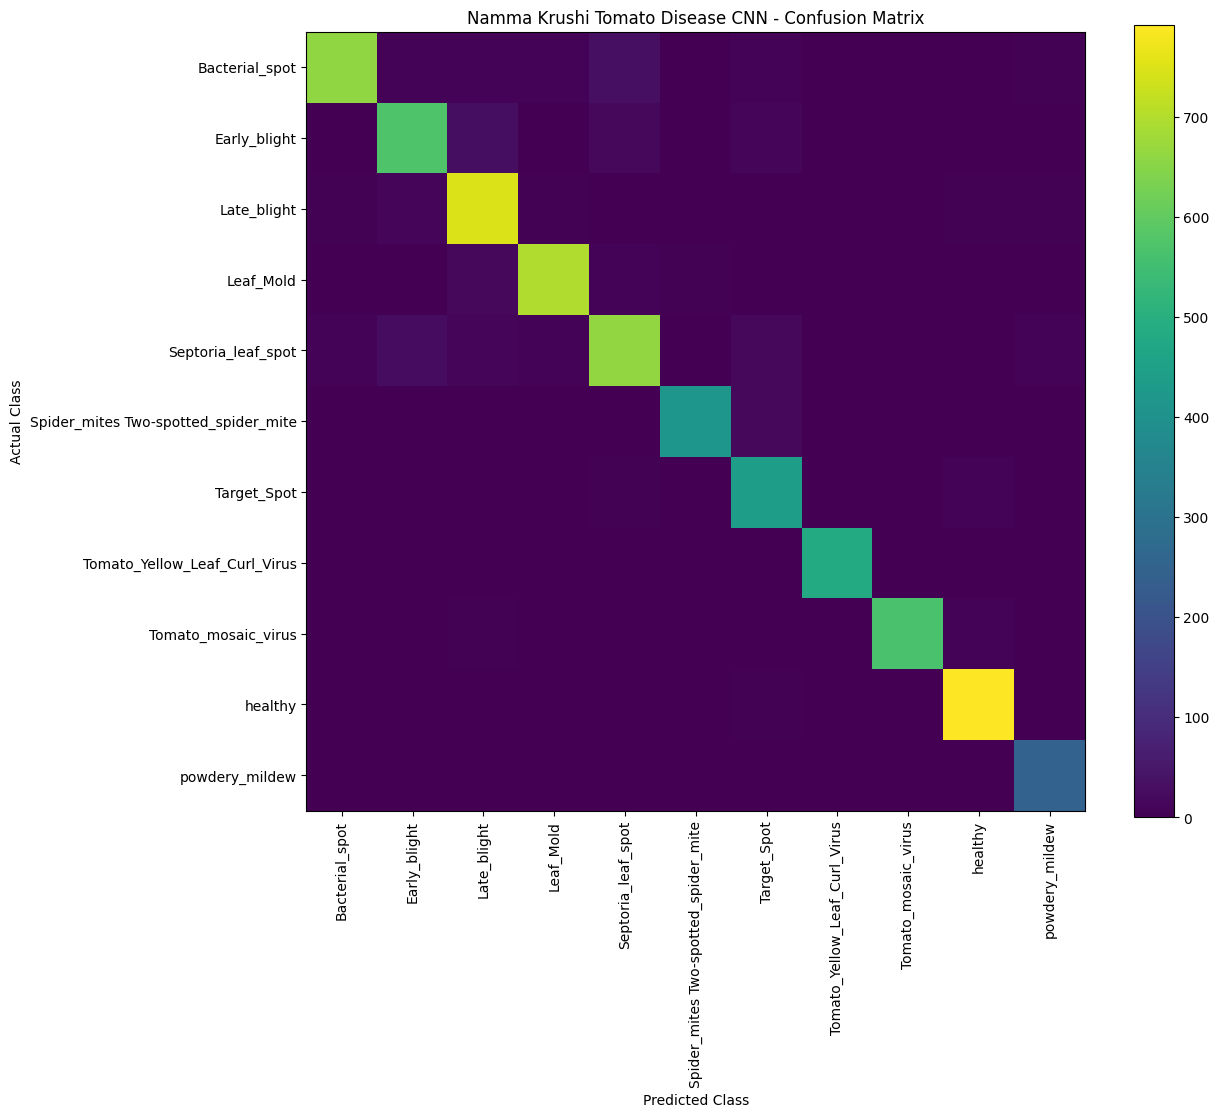


Total Test Images : 6683
Correct           : 6301
Misclassified     : 382

FINAL CNN EVALUATION COMPLETE

Evaluation artifacts:
 - classification_report.csv
 - confusion_matrix.csv
 - confusion_matrix.png
 - misclassified_images.csv
 - test_predictions.csv

Model artifacts:
 - cnn_metrics.json
 - image_config.json
 - tomato_disease_best.keras
 - tomato_disease_phase1_best.keras
 - tomato_disease_phase2_final.keras


In [15]:
# ============================================================
# NAMMA KRUSHI - FINAL CNN TEST EVALUATION
# ============================================================

import tensorflow as tf
import pandas as pd
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

BASE_DIR = Path("/kaggle/working/namma_krushi_disease")
MODEL_DIR = BASE_DIR / "model_artifacts"
EVAL_DIR = BASE_DIR / "evaluation"

EVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. LOAD BEST MODEL
# ------------------------------------------------------------

final_model = tf.keras.models.load_model(
    MODEL_DIR / "tomato_disease_best.keras"
)

print("Loaded final model:")
print(final_model.name)

# ------------------------------------------------------------
# 3. EVALUATE ON UNTOUCHED TEST SET
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL TEST EVALUATION")
print("=" * 80)

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print("\nTest Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))

# ------------------------------------------------------------
# 4. GET TEST PREDICTIONS
# ------------------------------------------------------------

probabilities = final_model.predict(
    test_ds,
    verbose=1
)

pred_labels = np.argmax(
    probabilities,
    axis=1
)

true_labels = test_df["label"].to_numpy()

assert len(pred_labels) == len(true_labels)

# ------------------------------------------------------------
# 5. MAIN METRICS
# ------------------------------------------------------------

macro_precision = precision_score(
    true_labels,
    pred_labels,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    true_labels,
    pred_labels,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    true_labels,
    pred_labels,
    average="macro",
    zero_division=0
)

weighted_f1 = f1_score(
    true_labels,
    pred_labels,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 80)
print("FINAL TEST METRICS")
print("=" * 80)

print("Accuracy        :", round(test_accuracy, 4))
print("Macro Precision :", round(macro_precision, 4))
print("Macro Recall    :", round(macro_recall, 4))
print("Macro F1        :", round(macro_f1, 4))
print("Weighted F1     :", round(weighted_f1, 4))

# ------------------------------------------------------------
# 6. CLASSIFICATION REPORT
# ------------------------------------------------------------

report = classification_report(
    true_labels,
    pred_labels,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(
    report
).transpose()

print("\n" + "=" * 80)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 80)

display(report_df.round(4))

report_df.to_csv(
    EVAL_DIR / "classification_report.csv"
)

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    true_labels,
    pred_labels,
    labels=list(range(NUM_CLASSES))
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

print("\nCONFUSION MATRIX:")
display(cm_df)

cm_df.to_csv(
    EVAL_DIR / "confusion_matrix.csv"
)

# ------------------------------------------------------------
# 8. CONFUSION MATRIX IMAGE
# ------------------------------------------------------------

plt.figure(figsize=(13, 11))

plt.imshow(cm)

plt.title(
    "Namma Krushi Tomato Disease CNN - Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(NUM_CLASSES),
    CLASS_NAMES,
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    CLASS_NAMES
)

plt.colorbar()

plt.tight_layout()

plt.savefig(
    EVAL_DIR / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 9. SAVE EVERY TEST PREDICTION
# ------------------------------------------------------------

prediction_df = test_df.copy()

prediction_df["predicted_label"] = pred_labels

prediction_df["predicted_class"] = [
    CLASS_NAMES[i]
    for i in pred_labels
]

prediction_df["confidence"] = np.max(
    probabilities,
    axis=1
)

prediction_df["correct"] = (
    prediction_df["label"]
    ==
    prediction_df["predicted_label"]
)

prediction_df.to_csv(
    EVAL_DIR / "test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 10. ERROR SUMMARY
# ------------------------------------------------------------

errors_df = prediction_df[
    prediction_df["correct"] == False
].copy()

errors_df = errors_df.sort_values(
    "confidence",
    ascending=False
)

errors_df.to_csv(
    EVAL_DIR / "misclassified_images.csv",
    index=False
)

print("\nTotal Test Images :", len(prediction_df))
print("Correct           :", int(prediction_df["correct"].sum()))
print("Misclassified     :", len(errors_df))

# ------------------------------------------------------------
# 11. SAVE METRICS JSON
# ------------------------------------------------------------

metrics = {

    "model":
        "EfficientNetB0 transfer learning + fine tuning",

    "classes":
        CLASS_NAMES,

    "number_of_classes":
        NUM_CLASSES,

    "test_images":
        int(len(test_df)),

    "test_loss":
        float(test_loss),

    "test_accuracy":
        float(test_accuracy),

    "macro_precision":
        float(macro_precision),

    "macro_recall":
        float(macro_recall),

    "macro_f1":
        float(macro_f1),

    "weighted_f1":
        float(weighted_f1),

    "image_size":
        [IMG_SIZE, IMG_SIZE],

    "best_validation_accuracy":
        0.932328
}

with open(
    MODEL_DIR / "cnn_metrics.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 12. SAVE DEPLOYMENT CLASS CONFIG
# ------------------------------------------------------------

image_config = {
    "image_height": IMG_SIZE,
    "image_width": IMG_SIZE,
    "channels": 3,
    "pixel_input_range": [0, 255],
    "model_family": "EfficientNetB0"
}

with open(
    MODEL_DIR / "image_config.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        image_config,
        f,
        indent=2
    )

print("\n" + "=" * 80)
print("FINAL CNN EVALUATION COMPLETE")
print("=" * 80)

print("\nEvaluation artifacts:")

for p in sorted(EVAL_DIR.iterdir()):
    print(" -", p.name)

print("\nModel artifacts:")

for p in sorted(MODEL_DIR.iterdir()):
    print(" -", p.name)

In [16]:
# ============================================================
# PACKAGE COMPLETE NAMMA KRUSHI TOMATO DISEASE CNN
# ============================================================

from pathlib import Path
import shutil
import os
import json

BASE_DIR = Path("/kaggle/working/namma_krushi_disease")
MODEL_DIR = BASE_DIR / "model_artifacts"

# ------------------------------------------------------------
# 1. Create deployment copy with clear final name
# ------------------------------------------------------------

best_model = MODEL_DIR / "tomato_disease_best.keras"

deployment_model = MODEL_DIR / "tomato_disease_model.keras"

if best_model.exists():
    shutil.copy2(
        best_model,
        deployment_model
    )

# ------------------------------------------------------------
# 2. Save final deployment summary
# ------------------------------------------------------------

deployment_info = {
    "project": "Namma Krushi",
    "module": "Tomato Disease Detection",
    "architecture": "EfficientNetB0",
    "training_method": "ImageNet transfer learning + fine tuning",

    "image_size": [224, 224],
    "channels": 3,

    "classes": CLASS_NAMES,

    "number_of_classes": len(CLASS_NAMES),

    "test_images": 6683,

    "test_accuracy": 0.9387,
    "macro_precision": 0.9400,
    "macro_recall": 0.9434,
    "macro_f1": 0.9408,
    "weighted_f1": 0.9389,

    "deployment_model": "tomato_disease_model.keras"
}

with open(
    MODEL_DIR / "deployment_info.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        deployment_info,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 3. Package entire disease-training output
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "/kaggle/working/namma_krushi_tomato_disease_complete",
    "zip",
    BASE_DIR
)

# ------------------------------------------------------------
# 4. Final output
# ------------------------------------------------------------

print("=" * 80)
print("TOMATO DISEASE PACKAGE CREATED")
print("=" * 80)

print("\nZIP:")
print(zip_path)

print("\nZIP size:")
print(
    round(
        os.path.getsize(zip_path) / (1024 * 1024),
        2
    ),
    "MB"
)

print("\nImportant deployment artifacts:")

important = [
    MODEL_DIR / "tomato_disease_model.keras",
    BASE_DIR / "class_names.json",
    BASE_DIR / "class_mapping.json",
    MODEL_DIR / "cnn_metrics.json",
    MODEL_DIR / "image_config.json",
    MODEL_DIR / "deployment_info.json",
    BASE_DIR / "evaluation" / "classification_report.csv",
    BASE_DIR / "evaluation" / "confusion_matrix.csv",
    BASE_DIR / "evaluation" / "confusion_matrix.png",
]

for p in important:
    print(
        "✅" if p.exists() else "❌",
        p.relative_to(BASE_DIR)
    )

print("\nPackage contents:")

for p in sorted(BASE_DIR.rglob("*")):
    if p.is_file():
        print(" -", p.relative_to(BASE_DIR))

TOMATO DISEASE PACKAGE CREATED

ZIP:
/kaggle/working/namma_krushi_tomato_disease_complete.zip

ZIP size:
102.42 MB

Important deployment artifacts:
✅ model_artifacts/tomato_disease_model.keras
✅ class_names.json
✅ class_mapping.json
✅ model_artifacts/cnn_metrics.json
✅ model_artifacts/image_config.json
✅ model_artifacts/deployment_info.json
✅ evaluation/classification_report.csv
✅ evaluation/confusion_matrix.csv
✅ evaluation/confusion_matrix.png

Package contents:
 - class_mapping.json
 - class_names.json
 - dataset_info.json
 - evaluation/classification_report.csv
 - evaluation/confusion_matrix.csv
 - evaluation/confusion_matrix.png
 - evaluation/misclassified_images.csv
 - evaluation/test_predictions.csv
 - model_artifacts/cnn_metrics.json
 - model_artifacts/deployment_info.json
 - model_artifacts/image_config.json
 - model_artifacts/tomato_disease_best.keras
 - model_artifacts/tomato_disease_model.keras
 - model_artifacts/tomato_disease_phase1_best.keras
 - model_artifacts/tomato_di

In [17]:
import os
from IPython.display import FileLink, display

os.chdir("/kaggle/working")

display(
    FileLink("namma_krushi_tomato_disease_complete.zip")
)

/kaggle/working/namma_krushi_tomato_disease_complete.zip

In [ ]:
import os

for f in os.listdir("/kaggle/working"):
    print(f)